# Автоматическая генерация признаков (Featuretools, DFS)

**Практическое задание**

Цель: построить матрицу признаков для таблицы `customers` на основе связанных таблиц `orders`, `products`, `order_items` с помощью глубокого синтеза признаков (DFS).

In [24]:
# Если featuretools не установлен — раскомментируйте:
# !pip install featuretools

import pandas as pd
import numpy as np
import featuretools as ft

print("featuretools version:", ft.__version__)

featuretools version: 1.31.0


## 1. Подготовка данных

Создаём 4 связанные таблицы:
- `customers` (client_id, name, join_date, region)
- `orders` (order_id, client_id, order_date, total_amount)
- `products` (product_id, category, price)
- `order_items` (item_id, order_id, product_id, quantity)

In [25]:
np.random.seed(42)

# --- customers ---
customers_df = pd.DataFrame({
    'client_id': range(1, 11),
    'name': [f'Client_{i}' for i in range(1, 11)],
    'join_date': pd.to_datetime([
        '2023-01-15', '2023-02-20', '2023-03-10', '2023-04-05', '2023-05-01',
        '2023-06-12', '2023-07-08', '2023-08-19', '2023-09-25', '2023-10-30'
    ]),
    'region': ['North', 'South', 'East', 'West', 'North',
               'South', 'East', 'West', 'North', 'South']
})

# --- products ---
products_df = pd.DataFrame({
    'product_id': range(101, 111),
    'category': ['Electronics', 'Books', 'Clothing', 'Food', 'Toys',
                 'Electronics', 'Books', 'Clothing', 'Food', 'Toys'],
    'price': [100.0, 15.5, 40.0, 5.0, 25.0, 200.0, 12.0, 55.0, 8.0, 30.0]
})

# --- orders ---
orders_df = pd.DataFrame({
    'order_id': range(1001, 1031),
    'client_id': np.random.choice(customers_df['client_id'], 30),
    'order_date': pd.to_datetime('2024-01-01') + pd.to_timedelta(
        np.random.randint(0, 180, 30), unit='D'
    ),
    'total_amount': np.round(np.random.uniform(10, 500, 30), 2)
})

# --- order_items ---
items_df = pd.DataFrame({
    'item_id': range(5001, 5081),
    'order_id': np.random.choice(orders_df['order_id'], 80),
    'product_id': np.random.choice(products_df['product_id'], 80),
    'quantity': np.random.randint(1, 6, 80)
})

# Если есть свои csv — раскомментируйте:
# customers_df = pd.read_csv('customers.csv')
# orders_df    = pd.read_csv('orders.csv')
# products_df  = pd.read_csv('products.csv')
# items_df     = pd.read_csv('order_items.csv')

print("customers:", customers_df.shape)
print("orders:   ", orders_df.shape)
print("products: ", products_df.shape)
print("items:    ", items_df.shape)

customers: (10, 4)
orders:    (30, 4)
products:  (10, 3)
items:     (80, 4)


In [26]:
customers_df.head()

,client_id,name,join_date,region
0,1,Client_1,2023-01-15,North
1,2,Client_2,2023-02-20,South
2,3,Client_3,2023-03-10,East
3,4,Client_4,2023-04-05,West
4,5,Client_5,2023-05-01,North


In [27]:
orders_df.head()

,order_id,client_id,order_date,total_amount
0,1001,7,2024-03-04,111.89
1,1002,4,2024-05-10,288.17
2,1003,8,2024-02-20,25.34
3,1004,5,2024-05-14,422.72
4,1005,7,2024-01-21,230.38


In [28]:
products_df.head()

,product_id,category,price
0,101,Electronics,100.0
1,102,Books,15.5
2,103,Clothing,40.0
3,104,Food,5.0
4,105,Toys,25.0


In [29]:
items_df.head()

,item_id,order_id,product_id,quantity
0,5001,1010,107,3
1,5002,1007,109,4
2,5003,1026,107,1
3,5004,1009,101,1
4,5005,1028,101,2


## 2. Создание EntitySet и связей

`EntitySet` — контейнер, хранящий таблицы и связи между ними.

In [30]:
es = ft.EntitySet(id='retail')

# customers
es = es.add_dataframe(
    dataframe_name='customers',
    dataframe=customers_df,
    index='client_id',
    time_index='join_date'
)

# products
es = es.add_dataframe(
    dataframe_name='products',
    dataframe=products_df,
    index='product_id'
)

# orders
es = es.add_dataframe(
    dataframe_name='orders',
    dataframe=orders_df,
    index='order_id',
    time_index='order_date'
)

# order_items
es = es.add_dataframe(
    dataframe_name='order_items',
    dataframe=items_df,
    index='item_id'
)

print(es)

Entityset: retail
  DataFrames:
    customers [Rows: 10, Columns: 4]
    products [Rows: 10, Columns: 3]
    orders [Rows: 30, Columns: 4]
    order_items [Rows: 80, Columns: 4]
  Relationships:
    No relationships


c:\OmSTU\Prodvinutie_metodi_7_semester\lectures\.venv\lib\site-packages\woodwork\type_sys\utils.py:33: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  pd.to_datetime(
c:\OmSTU\Prodvinutie_metodi_7_semester\lectures\.venv\lib\site-packages\woodwork\type_sys\utils.py:33: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  pd.to_datetime(
c:\OmSTU\Prodvinutie_metodi_7_semester\lectures\.venv\lib\site-packages\woodwork\type_sys\utils.py:33: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  pd.to_datetime(
c:\OmSTU\Prodvinutie_metodi_7_semester\lectures\.venv\lib\site-packages\woodwork\type

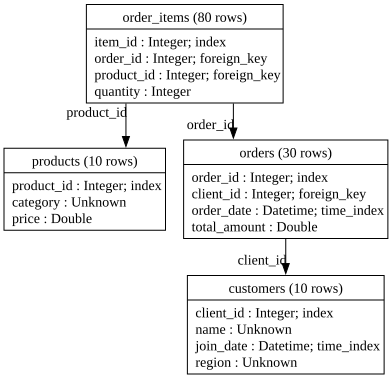

In [31]:
# customers -> orders
es = es.add_relationship('customers', 'client_id', 'orders', 'client_id')

# orders -> order_items
es = es.add_relationship('orders', 'order_id', 'order_items', 'order_id')

# products -> order_items
es = es.add_relationship('products', 'product_id', 'order_items', 'product_id')

es.plot()   # визуализация графа (если установлен graphviz)

## 3. Запуск глубокого синтеза признаков (DFS)

- `target_dataframe_name='customers'` — для какой таблицы строим признаки
- `max_depth=2` — используем связи через промежуточные таблицы
- `agg_primitives` — агрегации по связанным таблицам
- `trans_primitives` — преобразования внутри одной таблицы

In [32]:
feature_matrix, feature_defs = ft.dfs(
    entityset=es,
    target_dataframe_name='customers',
    agg_primitives=['sum', 'mean', 'count', 'max', 'min', 'std'],
    trans_primitives=['day', 'month', 'year', 'time_since_previous'],
    max_depth=2,
    verbose=True
)

Built 51 features


Elapsed: 00:00 | Progress: 100%|██████████


c:\OmSTU\Prodvinutie_metodi_7_semester\lectures\.venv\lib\site-packages\featuretools\computational_backends\feature_set_calculator.py:781: FutureWarning: The provided callable <function mean at 0x00000255FFF04820> is currently using SeriesGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  to_merge = base_frame.groupby(
c:\OmSTU\Prodvinutie_metodi_7_semester\lectures\.venv\lib\site-packages\featuretools\computational_backends\feature_set_calculator.py:781: FutureWarning: The provided callable <function sum at 0x00000255FFF008B0> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  to_merge = base_frame.groupby(
c:\OmSTU\Prodvinutie_metodi_7_semester\lectures\.venv\lib\site-packages\featuretools\computational_backends\feature_set_calculator.py:781: FutureWarning: The provide

## 4. Результаты

In [33]:
print("=== Размер матрицы признаков ===")
print(feature_matrix.shape)

print("\n=== Список сгенерированных признаков ===")
for i, f in enumerate(feature_defs, 1):
    print(f"{i:3d}. {f.get_name()}")

=== Размер матрицы признаков ===
(10, 51)

=== Список сгенерированных признаков ===
  1. COUNT(orders)
  2. MAX(orders.total_amount)
  3. MEAN(orders.total_amount)
  4. MIN(orders.total_amount)
  5. STD(orders.total_amount)
  6. SUM(orders.total_amount)
  7. COUNT(order_items)
  8. MAX(order_items.quantity)
  9. MEAN(order_items.quantity)
 10. MIN(order_items.quantity)
 11. STD(order_items.quantity)
 12. SUM(order_items.quantity)
 13. DAY(join_date)
 14. MONTH(join_date)
 15. TIME_SINCE_PREVIOUS(join_date)
 16. YEAR(join_date)
 17. MAX(orders.COUNT(order_items))
 18. MAX(orders.MEAN(order_items.quantity))
 19. MAX(orders.MIN(order_items.quantity))
 20. MAX(orders.STD(order_items.quantity))
 21. MAX(orders.SUM(order_items.quantity))
 22. MAX(orders.TIME_SINCE_PREVIOUS(order_date))
 23. MEAN(orders.COUNT(order_items))
 24. MEAN(orders.MAX(order_items.quantity))
 25. MEAN(orders.MEAN(order_items.quantity))
 26. MEAN(orders.MIN(order_items.quantity))
 27. MEAN(orders.STD(order_items.quanti

In [34]:
feature_matrix.head()

,COUNT(orders),MAX(orders.total_amount),MEAN(orders.total_amount),MIN(orders.total_amount),STD(orders.total_amount),SUM(orders.total_amount),COUNT(order_items),MAX(order_items.quantity),MEAN(order_items.quantity),MIN(order_items.quantity),...,SUM(orders.MAX(order_items.quantity)),SUM(orders.MEAN(order_items.quantity)),SUM(orders.MIN(order_items.quantity)),SUM(orders.STD(order_items.quantity)),SUM(orders.TIME_SINCE_PREVIOUS(order_date)),MAX(order_items.orders.total_amount),MEAN(order_items.orders.total_amount),MIN(order_items.orders.total_amount),STD(order_items.orders.total_amount),SUM(order_items.orders.total_amount)
client_id,,,,,,,,,,,,,,,,,,,,,
1,2,17.66,17.280000,16.90,0.537401,34.56,6,5.0,2.333333,1.0,...,6.0,4.000000,2.0,1.632993,1555200.0,17.66,17.153333,16.90,0.392462,102.92
2,2,482.98,319.075000,155.17,231.796674,638.15,3,5.0,3.000000,1.0,...,6.0,5.000000,4.0,1.414214,691200.0,482.98,264.440000,155.17,189.261192,793.32
3,3,464.06,399.603333,358.56,56.512836,1198.81,13,5.0,3.153846,1.0,...,13.0,9.366667,5.0,3.115128,345600.0,464.06,409.964615,358.56,52.481334,5329.54
4,3,306.92,286.766667,265.21,20.890381,860.30,9,5.0,2.666667,1.0,...,13.0,8.700000,5.0,5.178702,864000.0,306.92,293.484444,265.21,17.881365,2641.36
5,4,422.72,275.182500,90.98,137.115470,1100.73,7,5.0,3.428571,1.0,...,13.0,12.333333,11.0,1.154701,2678400.0,422.72,300.355714,90.98,111.163965,2102.49


## 5. Итоговый отчёт

| Параметр | Значение |
|---|---|
| Число таблиц | 4 |
| Число связей | 3 |
| max_depth | 2 |
| Размер feature_matrix | (10, 51) |
| Число признаков | 51 |
| Примеры признаков | COUNT(orders), SUM(orders.total_amount), MEAN(products.price) |

**Вывод:** DFS автоматически сгенерировал десятки признаков, описывающих поведение клиента (частота, суммы, статистики по товарам), без ручного написания агрегаций.